
 🛡️ INTRA-ROUND STEALTHINESS ANALYSIS (ATTACKER vs BENIGN)
Deze waarden tonen hoe 'zichtbaar' de aanvallers gemiddeld
en in het ergste geval zijn voor een inspectie-algoritme.
------------------------------------------------------------
--- Metric: L2_Distance ---
Gemiddelde kloof per ronde : 0.11395
Maximale kloof (Worst Case): 0.24485

--- Metric: Cosine_Similarity ---
Gemiddelde kloof per ronde : 0.00001
Maximale kloof (Worst Case): 0.00010

--- Metric: Magnitude ---
Gemiddelde kloof per ronde : 0.23231
Maximale kloof (Worst Case): 0.32145



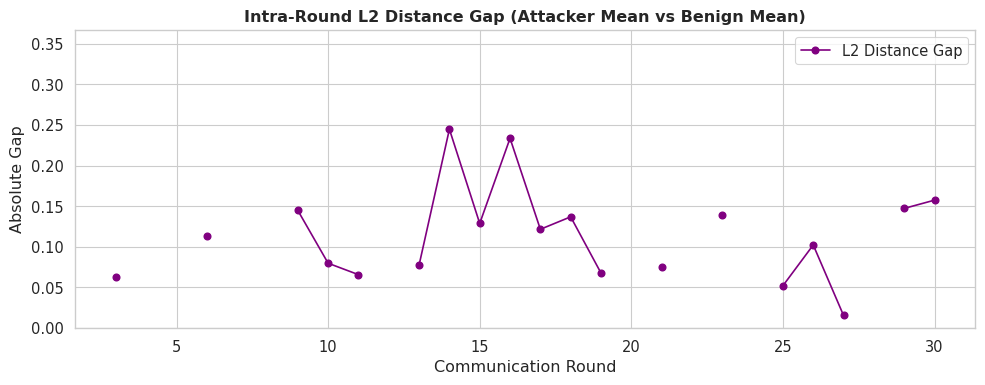

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import sys

sys.path.append(os.path.abspath('..'))

from utils.global_settings import ProjectPaths

def parse_client_log(file_path):
    data = []
    current_round = 0
    
    with open(file_path, 'r') as file:
        for line in file:
            round_match = re.search(r'ROUND (\d+)', line)
            if round_match:
                current_round = int(round_match.group(1))
                continue
            
            parts = line.split('|')
            if len(parts) == 5 and "CID" not in line:
                try:
                    cid = int(parts[0].strip())
                    client_type = parts[1].strip()
                    l2_dist = float(parts[2].strip())
                    cos_sim = float(parts[3].strip())
                    magnitude = float(parts[4].strip())
                    
                    data.append({
                        'Round': current_round,
                        'CID': cid,
                        'Type': client_type,
                        'L2_Distance': l2_dist,
                        'Cosine_Similarity': cos_sim,
                        'Magnitude': magnitude
                    })
                except ValueError:
                    pass

    return pd.DataFrame(data)

# --- RUN HET SCRIPT ---
# Vervang dit door jouw bestandspad
log_file = os.path.join(ProjectPaths.OUTPUT_DIR, "cluster", "2026-03-29-19-05-46", "client_update_log.txt")
df = parse_client_log(log_file)

# --- BEREKEN DE INTRA-ROUND VARIANTIE ---
# 1. Bereken de gemiddelde waarde per metric, per type, binnen ELKE ronde apart
round_means = df.groupby(['Round', 'Type'])[['L2_Distance', 'Cosine_Similarity', 'Magnitude']].mean().unstack('Type')

# 2. Bereken het absolute verschil (de 'kloof') tussen Attacker en Benign per ronde
# round_means heeft nu een MultiIndex kolomstructuur, bijv: ('L2_Distance', 'Attacker')
gaps = pd.DataFrame()
metrics = ['L2_Distance', 'Cosine_Similarity', 'Magnitude']

for m in metrics:
    # We berekenen de absolute afstand tussen het gemiddelde van de attackers en de benign clients in die ronde
    gaps[m + '_Gap'] = (round_means[(m, 'Attacker')] - round_means[(m, 'Benign')]).abs()

# 3. Bereken de uiteindelijke statistieken over al deze kloven
avg_gaps = gaps.mean()
max_gaps = gaps.max()

print("\n" + "="*60)
print(" 🛡️ INTRA-ROUND STEALTHINESS ANALYSIS (ATTACKER vs BENIGN)")
print("="*60)
print("Deze waarden tonen hoe 'zichtbaar' de aanvallers gemiddeld")
print("en in het ergste geval zijn voor een inspectie-algoritme.")
print("-" * 60)

for m in metrics:
    metric_name = m + '_Gap'
    print(f"--- Metric: {m} ---")
    print(f"Gemiddelde kloof per ronde : {avg_gaps[metric_name]:.5f}")
    print(f"Maximale kloof (Worst Case): {max_gaps[metric_name]:.5f}\n")

print("="*60)


# --- OPTIONEEL: Plot de variantie over de rondes ---
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
plt.figure(figsize=(10, 4))

plt.plot(gaps.index, gaps['L2_Distance_Gap'], color='purple', marker='o', label='L2 Distance Gap')
plt.title("Intra-Round L2 Distance Gap (Attacker Mean vs Benign Mean)", fontweight='bold')
plt.ylabel("Absolute Gap")
plt.xlabel("Communication Round")
plt.ylim(0, max_gaps['L2_Distance_Gap'] * 1.5) # Geef wat ademruimte aan de bovenkant
plt.legend()
plt.tight_layout()
plt.savefig("intra_round_variance.png", dpi=300)
# plt.show()